# The Fourier Transform and Fourier Space

---

> Author: <font color='#f78c40'>Samuel Farrens</font>
> Year: 2026
> Email: [samuel.farrens@cea.fr](mailto:samuel.farrens@cea.fr)
> Website: <a href="https://sfarrens.github.io" target="_blank">https://sfarrens.github.io</a>

## Contents

1. [Set-Up](#Set-Up)
1. [Introduction](#Introduction)
   * [Objective](#Objective)
   * [The Big Idea](#The-Big-Idea)
   * [Fourier Series](#Fourier-Series)
1. [The Winding Machine](#The-Winding-Machine)
1. [The Continuous Fourier Transform](#The-Continuous-Fourier-Transform)
   * [Definition](#Definition)
   * [Numerical Approximation](#Numerical-Approximation)
   * [Fourier Pairs](#Fourier-Pairs)
   * [Key Properties](#Key-Properties)
1. [The Discrete Fourier Transform](#The-Discrete-Fourier-Transform)
   * [From Continuous to Discrete](#From-Continuous-to-Discrete)
   * [The DFT as a Matrix](#The-DFT-as-a-Matrix)
   * [A Discrete Sine Wave](#A-Discrete-Sine-Wave)
   * [Negative Frequencies](#Negative-Frequencies)
   * [Sampling and Aliasing](#Sampling-and-Aliasing)
   * [Spectral Leakage and Windowing](#Spectral-Leakage-and-Windowing)
1. [The Fast Fourier Transform](#The-Fast-Fourier-Transform)
   * [Cooley-Tukey Algorithm](#Cooley-Tukey-Algorithm)
   * [Timing](#Timing)
1. [1D Example: Filtering a Noisy Recording](#1D-Example:-Filtering-a-Noisy-Recording)
1. [The 2D Fourier Transform](#The-2D-Fourier-Transform)
   * [2D Definition](#2D-Definition)
   * [Spatial Frequencies](#Spatial-Frequencies)
   * [Simple Shapes](#Simple-Shapes)
   * [A Real Image](#A-Real-Image)
   * [Amplitude vs Phase](#Amplitude-vs-Phase)
   * [Filtering Images](#Filtering-Images)
   * [Sparsity in Fourier Space](#Sparsity-in-Fourier-Space)
   * [Incomplete Fourier Sampling](#Incomplete-Fourier-Sampling)
1. [Exercises](#Exercises)
1. [Summary](#Summary)
1. [Further Resources](#Further-Resources)
1. [Hints](#Hints)

## Set-Up

Here we will import the packages needed throughout the notebook. Plotting and widget code lives in [`ft_plot.py`](ft_plot.py) (which must sit next to this notebook); all of the Fourier maths is written out below.

The interactive cells use [ipywidgets](https://ipywidgets.readthedocs.io/) with the [ipympl](https://matplotlib.org/ipympl/) backend, which updates figures in place as you move a slider. If `ipympl` is not installed (`pip install ipympl`), replace `%matplotlib widget` with `%matplotlib inline`: everything still works, but figures are redrawn after each change.

Users new to Jupyter notebooks should note that cells are executed by pressing <kbd>SHIFT</kbd>+<kbd>ENTER</kbd> (&#x21E7;+ &#x23ce;).

In [44]:
# Uncomment the following lines if you are running this on Google Colab.
# !pip install ipympl
# !wget -q https://raw.githubusercontent.com/sfarrens/learning/main/ft_plot.py
# from google.colab import output
# output.enable_custom_widget_manager()

In [45]:
# Interactive matplotlib backend.
%matplotlib widget

# Import the numpy package with the alias np.
import numpy as np

# Import matplotlib (and its bundled sample data).
import matplotlib.pyplot as plt
from matplotlib import cbook

# Import some display and timing tools.
from IPython.display import Audio, IFrame
from timeit import timeit

# Import notebook plotting functions.
import ft_plot

## Introduction

### <font color='#007acc'>Objective</font>

The objective of this notebook is to build an intuition for the Fourier transform (FT) and for what the information in *Fourier space* actually means. We go from the continuous FT, to the Discrete Fourier Transform (DFT) that we apply to sampled data, to the Fast Fourier Transform (FFT) algorithm that makes it practical, and then look at 1D (time-frequency) and 2D (space-spatial frequency) examples.

The winding machine section is inspired by the excellent 3Blue1Brown video [*But what is the Fourier Transform? A visual introduction*](https://www.youtube.com/watch?v=spUNpyF58BY). For more depth see:

* R. Bracewell, [*The Fourier Transform and Its Applications*](https://www.mheducation.com/highered/product/fourier-transform-its-applications-bracewell/M9780073039381.html) (2000)
* S. W. Smith, [*The Scientist and Engineer's Guide to Digital Signal Processing*](https://www.dspguide.com/) (free online)

### <font color='#007acc'>The Big Idea</font>

Any *reasonable* signal can be written as a sum of sinusoids. The FT tells us **how much** of each frequency is present (the *amplitude*) and **how it is shifted** (the *phase*). The signal and its FT contain exactly the same information, just expressed in a different basis.

The natural building block is the complex exponential. By Euler's formula

$$e^{i\theta} = \cos\theta + i\sin\theta,$$

$e^{2\pi i f t}$ is a point going round the unit circle $f$ times per second. Multiplying it by a complex number $A e^{i\phi}$ sets its amplitude $A$ and phase $\phi$.

<details>
<summary><b>Note:</b> what counts as a "reasonable" signal? (click to expand)</summary>

A signal is reasonable if its Fourier series or transform exists and adds back up to the signal. What that requires depends on the transform:

* **Fourier series** (periodic signals). The *Dirichlet conditions*: over one period $g$ is absolutely integrable, $\int_0^T |g(t)|\,dt < \infty$, with a finite number of maxima, minima and finite jumps. The series then converges to $g(t)$ wherever $g$ is continuous, and to the midpoint $\frac{1}{2}[g(t^-) + g(t^+)]$ at a jump.
* **Continuous FT** (all time). Either absolutely integrable, $\int |g|\,dt < \infty$, or finite energy, $\int |g|^2\,dt < \infty$ (*e.g.* the sinc, via Plancherel's theorem).
* **Distributions.** Signals that never decay, such as a pure sine, a constant, a delta function or a Dirac comb, have transforms only as generalised functions. For example, $\cos(2\pi f_0 t)$ transforms to two delta spikes at $\pm f_0$.
* **The DFT** (sampled data). Any finite list of $N$ numbers has an exact, invertible DFT. The caveats move to aliasing and leakage instead.

Signals that fail include growing exponentials such as $e^{t}$ (which need the Laplace transform) and pathological functions, such as one that equals 1 on the rationals and 0 elsewhere. Any signal you can actually record is reasonable.

</details>

In [46]:
# A complex exponential with amplitude A and frequency f, evaluated at time t.
def complex_exponential(A, f, t):

    return A * np.exp(2j * np.pi * f * t)

#### <font color='#fdbf00'>INTERACTIVE CELL</font>

In [47]:
######################################
# YOU SHOULD INTERACT WITH THIS CELL #
######################################

ft_plot.complex_exponential(complex_exponential)

Things to notice:

* $A$ sets the radius of the circle and $f$ the number of turns per second. A **negative frequency** simply turns clockwise.
* The real and imaginary parts are the shadows of the rotating point: $A\cos(2\pi f t)$ and $A\sin(2\pi f t)$.
* A real cosine is the sum of two points turning in opposite directions, $\cos(2\pi f t) = \frac{1}{2}\left(e^{2\pi i f t} + e^{-2\pi i f t}\right)$. This is why real signals have Fourier components at both $+f$ and $-f$.

### <font color='#007acc'>Fourier Series</font>

Fourier's original insight (1807) was that a periodic signal with period $T$ can be built from harmonics of the base frequency $1/T$

$$g(t) = \sum_{n=-\infty}^{\infty} c_n\, e^{2\pi i n t/T}, \qquad c_n = \frac{1}{T}\int_0^T g(t)\, e^{-2\pi i n t/T}\, dt,$$

where

* $g(t)$ is the **signal**: any (reasonably well-behaved) function that repeats every $T$ seconds, *i.e.* $g(t + T) = g(t)$.
* $n$ is the **harmonic number**: harmonic $n$ completes $n$ cycles per period, *i.e.* it has frequency $n/T$. Negative $n$ wind the other way round the circle.
* $c_n$ is the **Fourier coefficient** of harmonic $n$: a complex number whose magnitude $|c_n|$ gives the amplitude and whose argument $\arg c_n$ gives the phase of that harmonic. $c_0$ is simply the mean of $g$ over one period. Taken together, the coefficients as a function of frequency form the **spectrum** of $g$. The *amplitude spectrum* $|c_n|$ shows how much of each frequency the signal contains.

For a real signal $c_{-n} = \overline{c_n}$, where the overline denotes the **complex conjugate** (flip the sign of the imaginary part: $\overline{a + ib} = a - ib$). The $\pm n$ coefficients therefore have equal magnitudes and opposite phases, so each $\pm n$ pair combines into one real cosine, $2|c_n|\cos(2\pi n t/T + \arg c_n)$. This is why the coefficients plotted below are symmetric about $n = 0$.

To find how much of harmonic $n$ is present we **multiply by the complex sinusoid and average**. Hold on to that idea: it is the whole Fourier transform in a nutshell.

We will try this on three signals, each defined over one period $0 \leq t < T$ and repeated:

| Signal | $g(t)$ for $0 \leq t < T$ | $c_n$ |
|:--|:--|:--|
| Square wave | $+1$ for $t < T/2$, $-1$ for $t \geq T/2$ (*i.e.* $\mathrm{sgn}[\sin(2\pi t/T)]$) | $\dfrac{2}{i\pi n}$ for odd $n$, $0$ for even $n$ |
| Sawtooth wave | $2t/T - 1$ | $\dfrac{i}{\pi n}$ for $n \neq 0$ |
| Triangle wave | $2\,\vert 2t/T - 1\vert - 1$ | $\dfrac{4}{\pi^2 n^2}$ for odd $n$, $0$ for even $n$ |

All three have zero mean, so $c_0 = 0$.

In the figure below, the left panel shows $g(t)$ (grey) and the partial sum truncated at $|n| \leq n_{\max}$ (blue). The right panel shows the amplitude spectrum $|c_n|$ for each harmonic $n$ included in that sum. The coefficients are computed numerically by `series_coefficients`, so you can check them against the table.

In [48]:
# One period (T = 1 s) of three periodic signals.
T = 1.0
t = np.linspace(0, T, 2000, endpoint=False)

# Each value is an array of samples of g(t) on the grid t. The interactive cell
# passes the selected array as the argument g of series_coefficients.
shapes = {
    'Square wave': np.sign(np.sin(2 * np.pi * t / T)),
    'Sawtooth wave': 2 * t / T - 1,
    'Triangle wave': 2 * np.abs(2 * t / T - 1) - 1,
}

# Fourier series coefficients c_n for n = -n_max, ..., n_max (multiply and average).
# g: samples of the signal on the grid t (e.g. shapes['Square wave']).
# Returns the harmonic numbers n and the complex coefficients c_n.
def series_coefficients(g, t, n_max):

    n = np.arange(-n_max, n_max + 1)
    c = np.array([np.mean(g * np.exp(-2j * np.pi * k * t / T)) for k in n])
    return n, c

# Rebuild the signal from its coefficients: the partial sum of c_n exp(2 pi i n t / T).
def series_synthesis(n, c, t):

    return np.real(np.sum(c[:, None] * np.exp(2j * np.pi * n[:, None] * t / T), axis=0))

#### <font color='#fdbf00'>INTERACTIVE CELL</font>

In [49]:
######################################
# YOU SHOULD INTERACT WITH THIS CELL #
######################################

# For the selected shape and n_max this computes
#     n, c = series_coefficients(shapes[shape], t, n_max)
# and plots series_synthesis(n, c, t) (left) and |c| against n (right).
ft_plot.fourier_series(t, shapes, series_coefficients, series_synthesis)

Things to notice:

* The square and sawtooth waves need many harmonics because of their **sharp jumps**: sharp features require high frequencies. Their coefficients decay as $1/n$.
* The partial sums overshoot by about 9% next to a jump however many terms you add. This is the [Gibbs phenomenon](https://en.wikipedia.org/wiki/Gibbs_phenomenon).
* The triangle wave has no jumps (only kinks), so its coefficients decay as $1/n^2$ and a handful of terms are enough. **Smoother signals have spectra that decay faster**, *i.e.* their amplitude spectrum $|c_n|$ (right panel) falls off more quickly with $n$.

## The Winding Machine

Following 3Blue1Brown, take a signal $g(t)$ and **wrap it around the origin**: at each time $t$ draw a point at distance $g(t)$ from the origin, at an angle that rotates at a *winding frequency* $f$. In complex notation this is simply

$$g(t)\, e^{-2\pi i f t}.$$

Now track the **centre of mass** of the wrapped curve. For most values of $f$ the curve is spread evenly around the origin and the centre of mass stays near zero. When $f$ matches a frequency in the signal, the peaks of $g$ all land on the same side and the centre of mass jumps away from the origin.

We start with a 3 Hz signal shifted upwards so it is always positive (as in the video).

In [50]:
# A 3 Hz cosine, shifted up by 1.
t = np.linspace(0, 4.5, 4000)
g = np.cos(2 * np.pi * 3 * t) + 1

# Wrap the signal g(t) around the origin at winding frequency f.
def wind(g, t, f):

    return g * np.exp(-2j * np.pi * f * t)

#### <font color='#fdbf00'>INTERACTIVE CELL</font>

In [51]:
######################################
# YOU SHOULD INTERACT WITH THIS CELL #
######################################

ft_plot.winding_machine(t, g, wind)

Try the following:

* Set $f = 3$ Hz: every crest lands on the right, so the centre of mass moves far from the origin.
* Set $f = 0$: the signal is not wound at all, so the centre of mass is just the **mean** of $g$ (here 1). The zero-frequency coefficient is always the average value.
* Press play and watch the curve near $f = 3$: small differences in $f$ make the crests slowly drift round the circle and cancel out. A longer signal gives a narrower peak.

Now add a second frequency.

#### <font color='#fdbf00'>INTERACTIVE CELL</font>

In [52]:
######################################
# YOU SHOULD INTERACT WITH THIS CELL #
######################################

g2 = np.cos(2 * np.pi * 2 * t) + np.cos(2 * np.pi * 3 * t)
ft_plot.winding_machine(t, g2, wind)

Each frequency gives its own peak: the transform is **linear**, so the transform of a sum is the sum of the transforms. Try replacing a `cos` with a `sin`: the peak moves into the imaginary part (the y-coordinate of the centre of mass). That is phase information.

## The Continuous Fourier Transform

### <font color='#007acc'>Definition</font>

If we stop dividing by the duration (*i.e.* sum rather than average) and let the signal run over all time, the centre of mass becomes the **Fourier transform**

$$\hat{g}(f) = \mathcal{F}\{g\}(f) = \int_{-\infty}^{\infty} g(t)\, e^{-2\pi i f t}\, dt,$$

with the **inverse transform** rebuilding the signal from its frequencies

$$g(t) = \int_{-\infty}^{\infty} \hat{g}(f)\, e^{2\pi i f t}\, df.$$

* $\hat{g}(f)$ is complex: $|\hat{g}(f)|$ is the **amplitude** of frequency $f$ and $\arg\hat{g}(f)$ its **phase**.
* **Negative frequencies** are just winding the other way. For a real signal $\hat{g}(-f) = \overline{\hat{g}(f)}$ (*Hermitian symmetry*, where the overline is the complex conjugate), so the negative half carries no new information.
* This is the Fourier series in the limit $T\to\infty$: harmonics spaced by $1/T$ merge into a continuum.

> Physicists often use angular frequency $\omega = 2\pi f$, giving $\hat{g}(\omega) = \int g(t)e^{-i\omega t}dt$ with a factor $1/2\pi$ in the inverse. The content is identical; only the constants move. We use $f$ throughout, as does NumPy.

### <font color='#007acc'>Numerical Approximation</font>

A computer cannot integrate over all time, but for a function that decays we can use a Riemann sum. We sample the signal on a fine time grid $t_n$ with spacing $\Delta t$, and evaluate the transform on a grid of frequencies $f_j$

$$\hat{g}(f_j) \approx \sum_n g(t_n)\, e^{-2\pi i f_j t_n}\, \Delta t.$$

In the code, `t` holds the times $t_n$ and `f` holds the frequencies $f_j$. The sum over $n$ for every $f_j$ is then a single matrix-vector product, with matrix entries $e^{-2\pi i f_j t_n}$.

In [53]:
# Approximate the continuous FT, g_hat(f_j), from samples g(t_n).
# t: time grid t_n (uniform spacing dt), f: frequency grid f_j.
def cft(g, t, f):

    dt = t[1] - t[0]
    return np.exp(-2j * np.pi * np.outer(f, t)) @ g * dt

### <font color='#007acc'>Fourier Pairs</font>

A few functions have FTs that can be computed analytically. In each case $a$ sets the width.

| $g(t)$ | $\hat{g}(f)$ |
|:--|:--|
| Gaussian: $e^{-t^2/2a^2}$ | $a\sqrt{2\pi}\,e^{-2\pi^2a^2f^2}$ (another Gaussian) |
| Box: $1$ for $\vert t\vert < a$, else $0$ | $2a\,\mathrm{sinc}(2af)$, where $\mathrm{sinc}(x) = \sin(\pi x)/\pi x$ |
| Exponential: $e^{-\vert t\vert/a}$ | $2a / [1+(2\pi af)^2]$ (a Lorentzian) |
| Wave packet: $\cos(2\pi f_0 t)\,e^{-t^2/2a^2}$ | two Gaussians centred on $\pm f_0$ |

In [54]:
# Wave packet carrier frequency.
f0 = 1.5

# Gaussian transform (used twice).
gauss_ft = lambda f, a: a * np.sqrt(2 * np.pi) * np.exp(-2 * np.pi ** 2 * a ** 2 * f ** 2)

# Analytic Fourier pairs: name -> (g(t, a), g_hat(f, a)).
pairs = {
    'Gaussian': (
        lambda t, a: np.exp(-t ** 2 / (2 * a ** 2)),
        gauss_ft,
    ),
    'Box': (
        lambda t, a: (np.abs(t) < a).astype(float),
        lambda f, a: 2 * a * np.sinc(2 * a * f),
    ),
    'Exponential': (
        lambda t, a: np.exp(-np.abs(t) / a),
        lambda f, a: 2 * a / (1 + (2 * np.pi * a * f) ** 2),
    ),
    'Wave packet': (
        lambda t, a: np.cos(2 * np.pi * f0 * t) * np.exp(-t ** 2 / (2 * a ** 2)),
        lambda f, a: 0.5 * (gauss_ft(f - f0, a) + gauss_ft(f + f0, a)),
    ),
}

# Time grid t_n and frequency grid f_j.
t = np.linspace(-8, 8, 1601)
f = np.linspace(-4, 4, 801)

#### <font color='#fdbf00'>INTERACTIVE CELL</font>

In [55]:
######################################
# YOU SHOULD INTERACT WITH THIS CELL #
######################################

ft_plot.ft_pairs(t, f, pairs, cft)

The open circles are our numerical `cft`; the lines are the analytic results. Things to notice:

1. **Scaling:** a narrow function has a wide transform and *vice versa*. The product of the RMS widths obeys $\sigma_t\sigma_f \geq 1/4\pi$, with equality only for the Gaussian. This is the [uncertainty principle](https://en.wikipedia.org/wiki/Uncertainty_principle#Signal_processing). The readout is computed over the plotted range: for the box $\sigma_f$ actually diverges (the sinc tails decay slowly), and for the wave packet it is dominated by the separation of the two peaks.
2. **Shift:** moving $g$ in time leaves $|\hat{g}|$ unchanged and only rotates the phase: $g(t-t_0) \leftrightarrow e^{-2\pi i f t_0}\hat{g}(f)$. **Position information lives in the phase.**
3. **Edges:** the box's sharp edges produce slowly decaying ripples in frequency.
4. **Modulation:** multiplying by $\cos(2\pi f_0 t)$ copies the spectrum to $\pm f_0$. This is how AM radio works.
5. **Symmetry:** real, even functions have real transforms. Shift them and the transform becomes complex.

### <font color='#007acc'>Key Properties</font>

| Property | Time domain | Frequency domain |
|:--|:--|:--|
| Linearity | $a\,g(t) + b\,h(t)$ | $a\,\hat{g}(f) + b\,\hat{h}(f)$ |
| Shift | $g(t - t_0)$ | $e^{-2\pi i f t_0}\,\hat{g}(f)$ |
| Modulation | $e^{2\pi i f_0 t}\,g(t)$ | $\hat{g}(f - f_0)$ |
| Scaling | $g(at)$ | $\frac{1}{\vert a\vert}\,\hat{g}(f/a)$ |
| Convolution | $(g * h)(t)$ | $\hat{g}(f)\,\hat{h}(f)$ |
| Multiplication | $g(t)\,h(t)$ | $(\hat{g} * \hat{h})(f)$ |
| Derivative | $g'(t)$ | $2\pi i f\,\hat{g}(f)$ |
| Parseval | $\int \vert g(t)\vert^2 dt$ | $= \int \vert\hat{g}(f)\vert^2 df$ |

The **convolution theorem** is the workhorse: blurring an image by a telescope PSF, filtering a signal or smoothing with a kernel are all simple multiplications in Fourier space. [Parseval's theorem](https://en.wikipedia.org/wiki/Parseval%27s_theorem) says that the transform conserves **energy**. In signal processing, the energy of a signal is defined as

$$E = \int_{-\infty}^{\infty} |g(t)|^2\, dt \qquad \Big(\text{or } \sum_n |x_n|^2 \text{ for samples}\Big),$$

whatever the physical units of $g$. The name is borrowed from physics: if $g$ were a voltage across a $1\,\Omega$ resistor, $|g|^2$ would be the power dissipated and $E$ the total energy. Parseval's theorem says the same $E$ is obtained by integrating $|\hat{g}(f)|^2$ over frequency, so $|\hat{g}(f)|^2$ shows how the signal's energy is distributed across frequencies (the *energy spectral density*). Throughout this notebook, "most of the energy sits at low frequencies" means that most of $\int |\hat{g}(f)|^2\, df$ comes from small $|f|$.

We can check Parseval's theorem numerically.

In [56]:
# Check Parseval's theorem for a Gaussian (a = 0.7):
# energy = sum |g(t_n)|^2 dt in time, sum |g_hat(f_j)|^2 df in frequency.
g = pairs['Gaussian'][0](t, 0.7)
g_hat = cft(g, t, f)

print('Energy in time      :', np.sum(np.abs(g) ** 2) * (t[1] - t[0]))
print('Energy in frequency :', np.sum(np.abs(g_hat) ** 2) * (f[1] - f[0]))
print('Analytic (a sqrt(pi)):', 0.7 * np.sqrt(np.pi))

Energy in time      : 1.2407176956338346
Energy in frequency : 1.2407176956337818
Analytic (a sqrt(pi)): 1.240717695633861


## The Discrete Fourier Transform

### <font color='#007acc'>From Continuous to Discrete</font>

Real data are $N$ samples $x_n = g(n\Delta t)$, $n = 0,\dots,N-1$, covering a duration $T = N\Delta t$. Applying the Riemann sum and evaluating only at the frequencies $f_k = k/T$ gives $\hat{g}(f_k) \approx \Delta t\, X_k$, where

$$X_k = \sum_{n=0}^{N-1} x_n\, e^{-2\pi i kn/N}, \qquad x_n = \frac{1}{N}\sum_{k=0}^{N-1} X_k\, e^{2\pi i kn/N}$$

is the [Discrete Fourier Transform (DFT)](https://en.wikipedia.org/wiki/Discrete_Fourier_transform) and its inverse. The DFT is **exact and invertible** ($N$ numbers in, $N$ numbers out). It only approximates the continuous FT, and each of the two steps has a consequence:

| Step | Consequence |
|:--|:--|
| Sampling every $\Delta t$ | The spectrum becomes periodic with period $f_s = 1/\Delta t$. Frequencies above the **Nyquist frequency** $f_s/2$ *alias* onto lower ones. |
| Finite duration $T$ | Frequencies are only resolved every $\Delta f = 1/T$, and the signal is implicitly treated as periodic with period $T$. This causes **spectral leakage**. |

### <font color='#007acc'>The DFT as a Matrix</font>

Each $X_k$ is a weighted sum of all the samples, so the whole DFT can be written as one matrix-vector product

$$X = Wx, \qquad W_{kn} = e^{-2\pi i kn/N}.$$

Why write it this way?

* **The rows are the basis.** Row $k$ of $W$ is a complex sinusoid sampled at the $N$ times $t_n$, completing exactly $k$ cycles. $X_k$ is the inner product of the signal with that row. It measures how much of that sinusoid the signal contains (a discrete winding machine).
* **Linearity is explicit.** The DFT of a sum is the sum of the DFTs, so a mixture of sine waves gives a mixture of spikes (see the next section).
* **Nothing is lost.** The rows are orthogonal, $WW^H = NI$, where $W^H$ is the *conjugate transpose* of $W$ (conjugate every entry, then swap rows and columns), so the inverse is simply $W^{-1} = W^H/N$. The scaled matrix $W/\sqrt{N}$ is unitary. The DFT is a **change to an orthonormal basis** of sinusoids, which is also why energy is conserved (Parseval).
* **It connects to inverse problems.** In the language of sparse representations, a signal is written as $x = \phi\alpha$, here with the dictionary $\phi = W^H/N$, whose columns (the *atoms*) are sinusoids, and coefficients $\alpha = X$.
* **It shows the cost.** A dense $N\times N$ matrix-vector product needs $N^2$ operations. The FFT factorises $W$ into $\log_2 N$ sparse matrices, which is where its speed comes from.

In [57]:
# Build the N x N DFT matrix.
def dft_matrix(N):

    n = np.arange(N)
    k = n.reshape((N, 1))
    return np.exp(-2j * np.pi * k * n / N)

# Calculate the DFT of a given signal.
def dft(x):

    x = np.asarray(x, dtype=complex)
    return dft_matrix(x.size) @ x

In [58]:
# Compare with NumPy and check orthogonality.
x = np.random.default_rng(1).normal(size=64)
W = dft_matrix(16)

print('dft(x) matches np.fft.fft(x):', np.allclose(dft(x), np.fft.fft(x)))
print('W W^H = N I                 :', np.allclose(W @ W.conj().T, 16 * np.eye(16)))

dft(x) matches np.fft.fft(x): True
W W^H = N I                 : True


### <font color='#007acc'>A Discrete Sine Wave</font>

Let's sample a 2 Hz sine wave at 30 Hz for one second and take its DFT. `np.fft.fftfreq` gives the frequency of each bin (more on its ordering below).

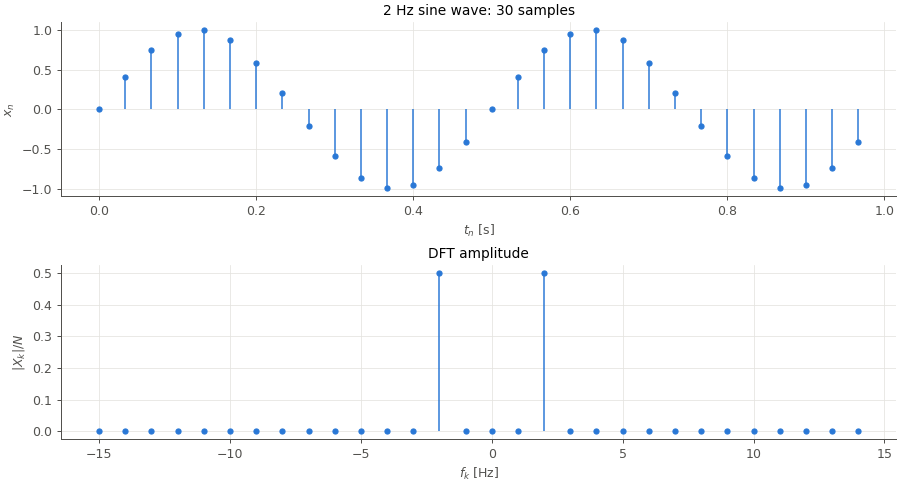

In [59]:
# Set the signal properties.
sampling_rate = 30.0
frequency = 2

# Sample times over 1 s and the corresponding signal.
t = np.arange(0, 1, 1 / sampling_rate)
x = np.sin(2 * np.pi * frequency * t)

# Frequency of each DFT bin and the DFT of the signal.
freqs = np.fft.fftfreq(t.size, d=1 / sampling_rate)
X = dft(x)

ft_plot.signal_and_spectrum(t, x, freqs, X, title='2 Hz sine wave')

Thirty non-zero samples become just two non-zero coefficients, at $\pm 2$ Hz, each of height $1/2$. The amplitude is split equally between the positive and negative frequency, exactly as with the $\pm n$ pairs of the Fourier series. The signal is *sparse* in Fourier space. (The two coefficients are in fact purely imaginary, since $\sin\theta = (e^{i\theta} - e^{-i\theta})/2i$. We plot $|X_k|$.)

Now mix up to three sine waves and add some noise. The slider colours match the waves and the shaded bars in the plot.

#### <font color='#fdbf00'>INTERACTIVE CELL</font>

In [60]:
######################################
# YOU SHOULD INTERACT WITH THIS CELL #
######################################

ft_plot.sine_mixer(dft)

Try the following:

* Each wave adds its own pair of spikes at $\pm f_j$ of height $A_j/2$. The spectrum of the sum is the sum of the spectra (linearity).
* Put two waves at the same frequency: their amplitudes add in a single bin.
* Add noise: it spreads evenly over all bins as a *noise floor*, while the spikes from the sine waves stay put. This is why denoising by thresholding in Fourier space works.
* Here $f_s = 64$ Hz and $T = 1$ s, so the bins are spaced by $\Delta f = 1/T = 1$ Hz and every integer frequency lands exactly on a bin. What happens between bins is covered under spectral leakage below.

### <font color='#007acc'>Negative Frequencies</font>

The DFT bins run from $k=0$ to $N-1$, so where are the negative frequencies? Move the slider beyond $k = N/2$.

#### <font color='#fdbf00'>INTERACTIVE CELL</font>

In [61]:
######################################
# YOU SHOULD INTERACT WITH THIS CELL #
######################################

ft_plot.dft_basis(dft_matrix(16))

For $k > N/2$ the samples of row $k$ are identical to those of a sinusoid with frequency $k - N$, which is negative. With only $N$ samples, the two cannot be told apart. Bins $N/2,\dots,N-1$ therefore hold the **negative frequencies**. `np.fft.fftfreq` gives the frequency of each bin and `np.fft.fftshift` reorders the output so that zero frequency is in the middle.

In [62]:
N, fs = 8, 8.0

print('bin index :', np.arange(N))
print('fftfreq   :', np.fft.fftfreq(N, d=1 / fs))
print('fftshift  :', np.fft.fftshift(np.fft.fftfreq(N, d=1 / fs)))

bin index : [0 1 2 3 4 5 6 7]
fftfreq   : [ 0.  1.  2.  3. -4. -3. -2. -1.]
fftshift  : [-4. -3. -2. -1.  0.  1.  2.  3.]


### <font color='#007acc'>Sampling and Aliasing</font>

The [Nyquist-Shannon sampling theorem](https://en.wikipedia.org/wiki/Nyquist%E2%80%93Shannon_sampling_theorem) states that a signal with no content above $f_{\max}$ is captured perfectly if $f_s > 2f_{\max}$. Otherwise higher frequencies fold back into the range $[-f_s/2, f_s/2]$.

#### <font color='#fdbf00'>INTERACTIVE CELL</font>

In [63]:
######################################
# YOU SHOULD INTERACT WITH THIS CELL #
######################################

ft_plot.aliasing()

Try the following:

* Raise $f_0$ above the Nyquist frequency $f_s/2$ and watch the spike fold back. The samples fit a lower-frequency alias (orange) exactly as well as the true signal.
* Set $f_0 = f_s$: every sample lands on a crest and the signal looks constant.
* The grey copies show why: sampling makes the spectrum periodic, and the DFT only shows the central period.

This is the *wagon-wheel* effect in films and the reason audio is sampled at 44.1 kHz (twice the ~20 kHz limit of human hearing).

### <font color='#007acc'>Spectral Leakage and Windowing</font>

**What are the bins?** The DFT only evaluates the spectrum at $N$ discrete frequencies $f_k = k/T = k f_s/N$, spaced by $\Delta f = 1/T$. Bin $k$ corresponds to the sinusoid that completes exactly $k$ cycles in the observation window (row $k$ of $W$). You can think of each bin as a frequency "bucket" of width $\Delta f$.

**Why does energy leak?** These $N$ sinusoids are orthogonal to each other. A signal with a whole number of cycles in the window *is* one of them, so it projects onto a single bin and is zero in all the others. A signal *between* bins is not orthogonal to any of them, so it projects a little onto every bin, and its energy leaks across the whole spectrum. In the time domain, the DFT assumes the window repeats forever, and a non-integer number of cycles leaves a jump where the copies join.

Equivalently, a finite observation multiplies the signal by a box, so its spectrum is convolved with a sinc. The DFT samples this smeared spectrum (grey curve) at the bins (blue). The sinc has a **main lobe** (the peak, 2 bins wide) and **side lobes** (the ripples), which decay slowly: the first is only 13 dB below the peak.

**Why care about side lobes?**

* **Masking.** A weak signal near a strong one can be buried under the strong one's side lobes, *e.g.* a faint spectral line next to a bright one. The side-lobe level limits the usable *dynamic range*.
* **Biased amplitudes.** Between bins the peak is split over neighbouring bins, so the measured amplitude is too low (by up to 36% without a window). This is called *scalloping loss*.
* **A false floor.** Leakage from many components builds up into a broadband floor that looks like noise.

A **window function** tapers the ends of the data to zero, removing the jump. This lowers the side lobes but widens the main lobe, so nearby frequencies become harder to separate (worse resolution).

| Window | Highest side lobe | Main lobe width |
|:--|:--|:--|
| Rectangular (none) | $-13$ dB | 2 bins |
| Hann | $-31$ dB | 4 bins |
| Blackman | $-58$ dB | 6 bins |

> Decibels are a logarithmic scale for amplitude ratios, $20\log_{10}(a/a_{\max})$: $-20$ dB is 10 times smaller and $-60$ dB is 1000 times smaller.

#### <font color='#fdbf00'>INTERACTIVE CELL</font>

In [64]:
######################################
# YOU SHOULD INTERACT WITH THIS CELL #
######################################

ft_plot.leakage()

Try the following:

* With exactly 8.00 cycles the tone *is* bin 8's sinusoid. Every other bin lands on a zero of the sinc, so there is no leakage. At 8.50 the leakage is at its worst, and the peak is split between bins 8 and 9 (scalloping).
* Tick *add a weak tone*. This adds a second tone 40 dB (100 times) weaker, 8 bins higher. With 8.50 cycles and no window, it is lost under the side lobes. Switch to Hann and then Blackman, and it reappears.
* With the Blackman window, notice how much wider the main peak has become. That is the price of lower side lobes.
* Zero-padding (the grey curve) *interpolates* the spectrum but does not improve resolution. Only a longer observation ($\Delta f = 1/T$) does.

## The Fast Fourier Transform

The matrix DFT needs $N^2$ complex multiplications. For $N = 10^6$ (a megapixel image or about 20 s of audio) that is $10^{12}$ operations. The [Fast Fourier Transform (FFT)](https://en.wikipedia.org/wiki/Fast_Fourier_transform) computes exactly the same result in $\mathcal{O}(N\log N)$, about $2\times10^7$ operations. It is one of the most important algorithms ever written.

### <font color='#007acc'>Cooley-Tukey Algorithm</font>

For $N$ a power of two, split the sum into even and odd samples

$$X_k = \underbrace{\sum_{m=0}^{N/2-1} x_{2m}\, e^{-2\pi i km/(N/2)}}_{E_k} + e^{-2\pi i k/N}\underbrace{\sum_{m=0}^{N/2-1} x_{2m+1}\, e^{-2\pi i km/(N/2)}}_{O_k}.$$

$E_k$ and $O_k$ are DFTs of size $N/2$, which are periodic in $k$ with period $N/2$. The *twiddle factor* $W_N^k = e^{-2\pi i k/N}$ satisfies $W_N^{k+N/2} = -W_N^k$, so for $k = 0,\dots,N/2-1$

$$X_k = E_k + W_N^k O_k, \qquad X_{k+N/2} = E_k - W_N^k O_k.$$

Applying this recursively gives $\log_2 N$ levels, each costing $\mathcal{O}(N)$. The idea is usually credited to Cooley and Tukey (1965), although Gauss used it around 1805.

In [65]:
# Recursive radix-2 Cooley-Tukey FFT (N must be a power of 2).
def fft_radix2(x):

    x = np.asarray(x, dtype=complex)
    N = x.size
    if N == 1:
        return x

    even = fft_radix2(x[0::2])
    odd = fft_radix2(x[1::2])
    twiddle = np.exp(-2j * np.pi * np.arange(N // 2) / N) * odd

    return np.concatenate([even + twiddle, even - twiddle])

In [66]:
x = np.random.default_rng(2).normal(size=1024)
print('fft_radix2(x) matches np.fft.fft(x):', np.allclose(fft_radix2(x), np.fft.fft(x)))

fft_radix2(x) matches np.fft.fft(x): True


Unrolling the recursion gives the classic *butterfly* diagram. Each stage combines pairs of values with one multiplication by a twiddle factor.

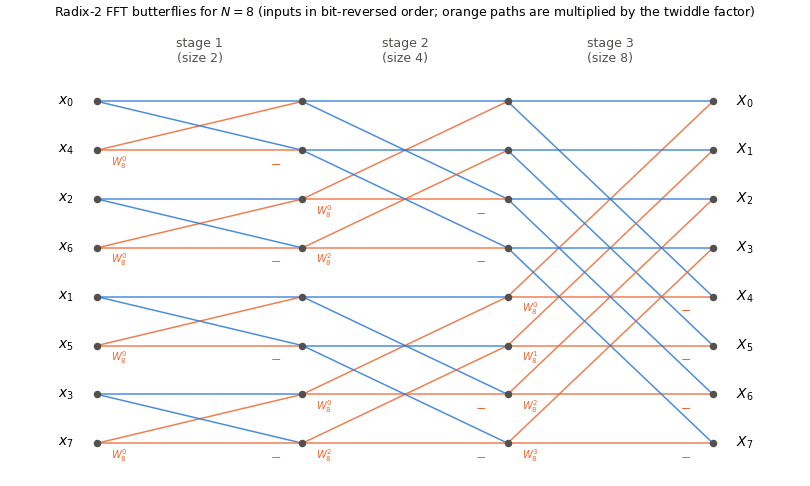

In [67]:
ft_plot.butterfly_diagram(8)

### <font color='#007acc'>Timing</font>

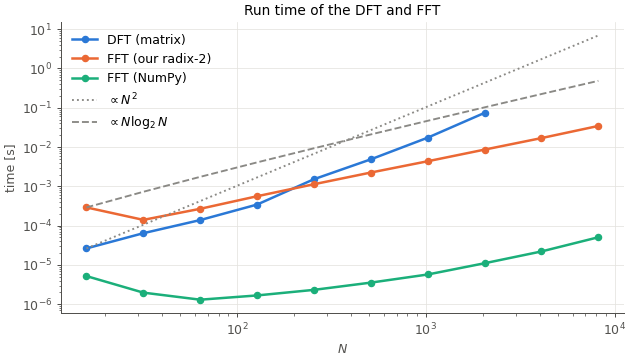

In [68]:
# Time the three implementations for increasing N.
sizes = 2 ** np.arange(4, 14)
timings = {'DFT (matrix)': [], 'FFT (our radix-2)': [], 'FFT (NumPy)': []}

for N in sizes:
    x = np.random.default_rng(0).normal(size=N)
    if N <= 2048:
        timings['DFT (matrix)'].append(timeit(lambda: dft(x), number=3) / 3)
    timings['FFT (our radix-2)'].append(timeit(lambda: fft_radix2(x), number=3) / 3)
    timings['FFT (NumPy)'].append(timeit(lambda: np.fft.fft(x), number=50) / 50)

ft_plot.timing_plot(sizes, timings)

Our pure-Python FFT carries a lot of overhead, but it scales as $N\log N$ and soon overtakes the matrix DFT. NumPy's FFT ([pocketfft](https://gitlab.mpcdf.mpg.de/mtr/pocketfft), written in C) is orders of magnitude faster again and handles any $N$, not just powers of two.

A few practical tips:

* Use `np.fft.rfft` for real input. It returns only the non-negative frequencies and is about twice as fast.
* `scipy.fft` adds multithreading (`workers=`) and `next_fast_len` for choosing efficient padded sizes.
* `norm='ortho'` makes the forward and inverse transforms symmetric (unitary). The default puts $1/N$ on the inverse.

## 1D Example: Filtering a Noisy Recording

Let's record an A major chord (440, 554 and 659 Hz) contaminated by mains hum (50 and 150 Hz) and white noise (hiss). Have a listen.

In [69]:
# Sampling rate [Hz] and time samples (2 s).
fs = 8000
t = np.arange(0, 2, 1 / fs)
rng = np.random.default_rng(42)

# Clean chord, hum and noisy recording.
chord = sum(np.sin(2 * np.pi * f * t) for f in (440.0, 554.37, 659.25)) / 3
hum = 0.6 * np.sin(2 * np.pi * 50 * t) + 0.3 * np.sin(2 * np.pi * 150 * t)
recording = chord + hum + 0.4 * rng.normal(size=t.size)

Audio(recording, rate=fs)

In the time domain the components are hopelessly mixed, but in Fourier space each tone is a separate spike. Filtering is then trivial: set the unwanted coefficients to zero and transform back.

In [70]:
# Ideal band-pass filter: zero all frequencies outside [f_lo, f_hi].
def bandpass(y, fs, f_lo, f_hi):

    Y = np.fft.rfft(y)
    f = np.fft.rfftfreq(y.size, d=1 / fs)
    Y[(f < f_lo) | (f > f_hi)] = 0
    return np.fft.irfft(Y, n=y.size)

#### <font color='#fdbf00'>INTERACTIVE CELL</font>

In [71]:
######################################
# YOU SHOULD INTERACT WITH THIS CELL #
######################################

ft_plot.audio_filter(t, recording, fs, bandpass, clean=chord)

Try a pass band of about 300 to 1000 Hz, then listen to the result. Notice:

* The hum is removed completely, because it sits in a separate part of Fourier space.
* The noise **inside** the pass band remains. White noise has equal power at all frequencies, so a band-pass filter cannot separate it from the chord. Thresholding the coefficients instead exploits the fact that the chord is *sparse* in Fourier space.
* A brick-wall filter multiplies the spectrum by a box, which convolves the signal with a sinc and causes ringing. Practical filters taper the edges.

## The 2D Fourier Transform

### <font color='#007acc'>2D Definition</font>

In 2D, time $t$ becomes position $(x, y)$ and frequency $f$ becomes **spatial frequency** $(u, v)$, measured in cycles per unit length (for images, cycles per pixel)

$$\hat{g}(u, v) = \iint g(x, y)\, e^{-2\pi i (ux + vy)}\, dx\, dy.$$

For an image $x_{m,n}$ with $M$ rows ($y$ direction) and $N$ columns ($x$ direction), the 2D DFT is

$$X_{k_y,k_x} = \sum_{m=0}^{M-1}\sum_{n=0}^{N-1} x_{m,n}\, e^{-2\pi i (k_y m/M + k_x n/N)},$$

where the integers $k_x$ and $k_y$ count the **number of cycles across the whole image** in the $x$ and $y$ directions. They are the 2D equivalent of the bin index $k$, and they relate to spatial frequency by $u = k_x/N$ and $v = k_y/M$ (cycles per pixel), just as $f_k = k/T$ in 1D.

The exponential factorises, so the 2D transform is **separable**: a 1D FFT along every row followed by a 1D FFT along every column.

In [72]:
img = np.random.default_rng(0).normal(size=(32, 48))
rows_then_cols = np.fft.fft(np.fft.fft(img, axis=1), axis=0)

print('Row and column FFTs match np.fft.fft2:', np.allclose(rows_then_cols, np.fft.fft2(img)))

Row and column FFTs match np.fft.fft2: True


### <font color='#007acc'>Spatial Frequencies</font>

In 1D each Fourier coefficient is a sinusoid. In 2D it is a **plane wave**. In the demo below, the $N \times N$ image is

$$\cos\left(2\pi\,\frac{k_x x + k_y y}{N} + \varphi\right),$$

with pixel coordinates $(x, y)$ and phase $\varphi$. This is a pattern of stripes whose crests run perpendicular to the **wave vector** $(k_x, k_y)$ (green arrow), with a wavelength of $N/\sqrt{k_x^2+k_y^2}$ pixels. Each point in Fourier space is one such stripe pattern:

* **distance from the centre** tells you how fine the stripes are
* **direction** tells you their orientation.

> **The $uv$-plane or $k$-space?** They are the same space (the Fourier space of an image), but different fields use different names and units.
>
> * The **$uv$-plane** $(u, v)$ is spatial frequency in cycles per unit length (here cycles per pixel). The name is standard in optics and radio interferometry, where $(u, v)$ is the separation between two antennas measured in wavelengths.
> * **$k$-space** comes from physics, where the wave vector $\mathbf{k} = 2\pi(u, v)$ is measured in *radians* per unit length (the spatial version of $\omega = 2\pi f$). MRI also calls its Fourier space *k-space*, but usually measures $k$ in cycles per unit length, *i.e.* without the $2\pi$.
> * In this notebook, $(k_x, k_y)$ are the integer DFT indices (cycles per image), so $(u, v) = (k_x/N, k_y/N)$ for an $N\times N$ image.
>
> Whichever convention you meet, check whether it includes the factor of $2\pi$.

#### <font color='#fdbf00'>INTERACTIVE CELL</font>

In [73]:
######################################
# YOU SHOULD INTERACT WITH THIS CELL #
######################################

ft_plot.plane_wave()

A real-valued image gives two spikes at $\pm(k_x, k_y)$ (Hermitian symmetry again). Changing the phase $\varphi$ slides the stripes but leaves $|F|$ untouched.

### <font color='#007acc'>Simple Shapes</font>

#### <font color='#fdbf00'>INTERACTIVE CELL</font>

In [74]:
######################################
# YOU SHOULD INTERACT WITH THIS CELL #
######################################

ft_plot.shapes_2d()

Try the following:

* **Rotate** a shape: its spectrum rotates by the same angle.
* **Resize** it: the bigger the object, the smaller its spectrum. A rectangle that is long in $x$ has a spectrum that is long in $y$.
* **Shift** it: the amplitude spectrum does not change at all (the shift is in the phase).
* The **disc** gives the [Airy pattern](https://en.wikipedia.org/wiki/Airy_disk), which is why a telescope with a circular aperture has a ringed PSF.
* A **slit** gives a streak perpendicular to it, and a **lattice** gives another lattice with inverse spacing (the *reciprocal lattice* of X-ray crystallography).

### <font color='#007acc'>A Real Image</font>

We will use two images that ship with Matplotlib: a portrait of computing pioneer Grace Hopper and an MRI brain scan.

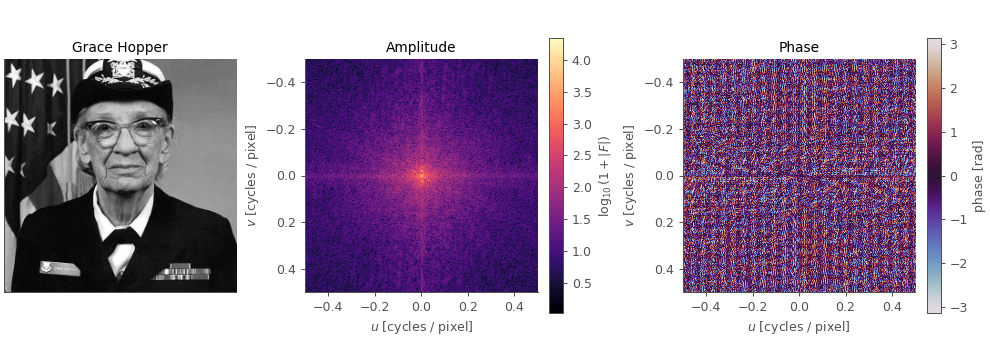

In [75]:
# Grace Hopper portrait: grey-scale, cropped to 512 x 512 and binned 2 x 2 to 256 x 256.
with cbook.get_sample_data('grace_hopper.jpg') as file:
    hopper = plt.imread(file).mean(axis=2)[40:552, :] / 255
hopper = hopper.reshape(256, 2, 256, 2).mean(axis=(1, 3))

# MRI brain slice (256 x 256).
with cbook.get_sample_data('s1045.ima.gz') as file:
    brain = np.frombuffer(file.read(), np.uint16).reshape(256, 256).astype(float)
brain /= brain.max()

ft_plot.show_spectrum(hopper, 'Grace Hopper')

How to read the amplitude spectrum:

* **The centre** $(0, 0)$ is the mean brightness. Most of the energy sits at low frequencies, which describe the large, smooth regions. For natural images the amplitude falls off roughly as $1/|k|$.
* **Further out** are the fine details: edges, textures, hair and noise.
* **Streaks** point perpendicular to strong straight edges in the image.
* **The bright cross** along the axes is an artefact. The DFT treats the image as a periodic tile, and its left/right and top/bottom borders do not match, which creates artificial edges. A window removes it, as in 1D:

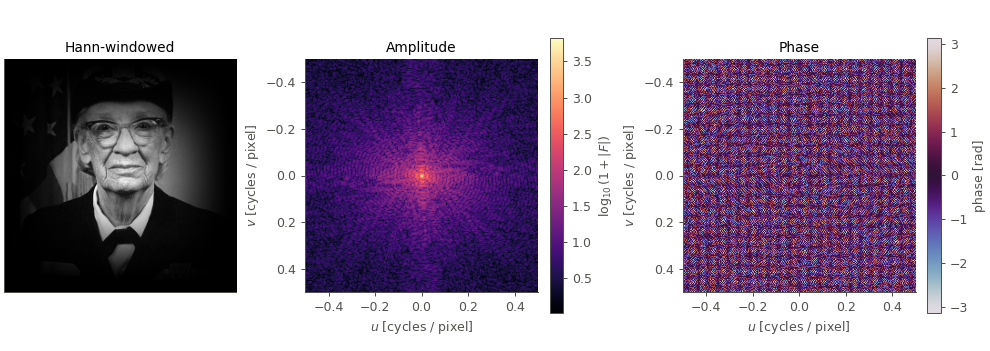

In [76]:
window_2d = np.outer(np.hanning(256), np.hanning(256))
ft_plot.show_spectrum(hopper * window_2d, 'Hann-windowed')

The phase, on the other hand, looks like noise. Does it matter?

### <font color='#007acc'>Amplitude vs Phase</font>

Let's combine the amplitude of one image with the phase of the other ([Oppenheim and Lim, 1981](https://ieeexplore.ieee.org/document/1456290)).

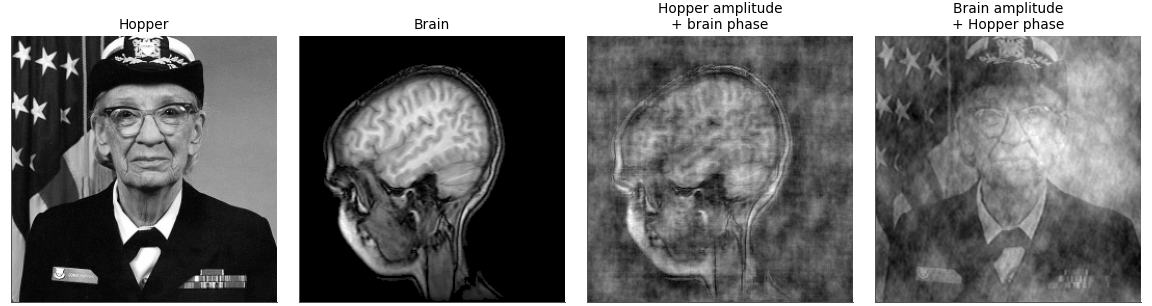

In [77]:
F_hopper, F_brain = np.fft.fft2(hopper), np.fft.fft2(brain)

# Amplitude of one image with the phase of the other.
hopper_amp_brain_phase = np.fft.ifft2(np.abs(F_hopper) * np.exp(1j * np.angle(F_brain))).real
brain_amp_hopper_phase = np.fft.ifft2(np.abs(F_brain) * np.exp(1j * np.angle(F_hopper))).real

ft_plot.show_images(
    [hopper, brain, hopper_amp_brain_phase, brain_amp_hopper_phase],
    ['Hopper', 'Brain', 'Hopper amplitude\n+ brain phase', 'Brain amplitude\n+ Hopper phase'],
)

The images follow the **phase**. Phase encodes *where* structures are (recall the shift theorem): where edges line up and features sit. Amplitude encodes *how much* of each scale and orientation is present, which is broadly similar for all natural images.

### <font color='#007acc'>Filtering Images</font>

Thanks to the convolution theorem, filtering an image means multiplying its FT by a mask. Here we select spatial frequencies by their radius $r = \sqrt{u^2 + v^2}$.

In [78]:
# Mask keeping r_min <= r <= r_max [cycles/pixel], in (unshifted) FFT order.
def radial_mask(shape, r_min, r_max, smooth=False):

    v = np.fft.fftfreq(shape[0])[:, None]
    u = np.fft.fftfreq(shape[1])[None, :]
    r = np.hypot(u, v)

    if not smooth:
        return ((r >= r_min) & (r <= r_max)).astype(float)

    # Gaussian tapers instead of sharp cuts.
    low = np.exp(-r ** 2 / (2 * max(r_max, 1e-3) ** 2)) if r_max < 1 else 1.0
    high = 1 - np.exp(-r ** 2 / (2 * r_min ** 2)) if r_min > 0 else 1.0
    return low * high * np.ones(shape)

# Filter an image by multiplying its FT by a mask.
def fourier_filter(img, mask):

    return np.fft.ifft2(np.fft.fft2(img) * mask).real

#### <font color='#fdbf00'>INTERACTIVE CELL</font>

In [79]:
######################################
# YOU SHOULD INTERACT WITH THIS CELL #
######################################

ft_plot.image_filter(hopper, radial_mask, fourier_filter)

Try the following:

* **Low-pass** with a sharp cut gives blurring plus ripples around edges (the 2D Gibbs phenomenon). Tick *smooth edges* and the ripples disappear.
* **High-pass** keeps only edges and fine texture, which is a basic edge detector.
* **Band-pass** isolates features of a given size. Decomposing an image into a set of such bands is the idea behind wavelets and the starlet transform.

### <font color='#007acc'>Sparsity in Fourier Space</font>

Because most of the energy sits in relatively few coefficients, an image can be approximated by keeping only the largest ones.

In [80]:
# Keep only the given fraction of largest-amplitude Fourier coefficients.
def keep_largest(F, fraction):

    n_keep = max(1, int(fraction * F.size))
    threshold = np.sort(np.abs(F).ravel())[-n_keep]
    return F * (np.abs(F) >= threshold)

#### <font color='#fdbf00'>INTERACTIVE CELL</font>

In [81]:
######################################
# YOU SHOULD INTERACT WITH THIS CELL #
######################################

ft_plot.compression(hopper, keep_largest)

A few percent of the coefficients already give a recognisable image, and the kept coefficients cluster at low frequencies. This *approximate sparsity* is what compression (JPEG uses a close cousin, the discrete cosine transform) and sparse regularisation exploit. The residual shows what is lost first: edges and fine texture.

### <font color='#007acc'>Incomplete Fourier Sampling</font>

Some instruments measure Fourier space directly. **MRI** scanners acquire *k-space*, and **radio interferometers** measure *visibilities*, which are samples of the FT of the sky in the $uv$-plane. Fourier coefficients that are not measured are effectively set to zero. Multiplying by the sampling mask $M$ convolves the image with the FT of $M$ (the PSF or *dirty beam*).

#### <font color='#fdbf00'>INTERACTIVE CELL</font>

In [82]:
######################################
# YOU SHOULD INTERACT WITH THIS CELL #
######################################

ft_plot.kspace_sampling(brain)

Each sampling pattern leaves a different artefact:

* **Low frequencies only:** a blurred image, because the fine detail lives at high frequencies.
* **Random points:** noise-like, *incoherent* artefacts spread over the whole image. Compressed sensing exploits exactly this.
* **Random + dense centre:** much better at the same sampling fraction, since the centre holds most of the energy.
* **Every n-th row:** $n$ overlapping ghost copies of the image. This is aliasing in 2D, and the reason fast MRI is non-trivial.
* **Radial spokes:** streak artefacts, familiar from CT and radio imaging.

## Exercises

### <font color='#e42d2f'>EXERCISE</font> 1: Inverse DFT

Implement the inverse DFT, $x_n = \frac{1}{N}\sum_k X_k e^{2\pi i kn/N}$, using `dft_matrix`, and check that it recovers the original signal.

In [83]:
##############################
# YOU NEED TO EDIT THIS CELL #
##############################

# Calculate the inverse DFT of a given spectrum.
def idft(X):

    return None

x = np.random.default_rng(3).normal(size=32)
if idft(dft(x)) is not None:
    print('Round trip recovers x:', np.allclose(idft(dft(x)), x))

### <font color='#e42d2f'>EXERCISE</font> 2: Remove Periodic Noise

The image below has been corrupted by interference stripes, a common problem with scanners and detector read-out electronics. Find the stripes in Fourier space and build a mask, `notch`, that removes them.

> Tip: the spikes are single pixels, so use the zoom tool in the figure toolbar to find them.

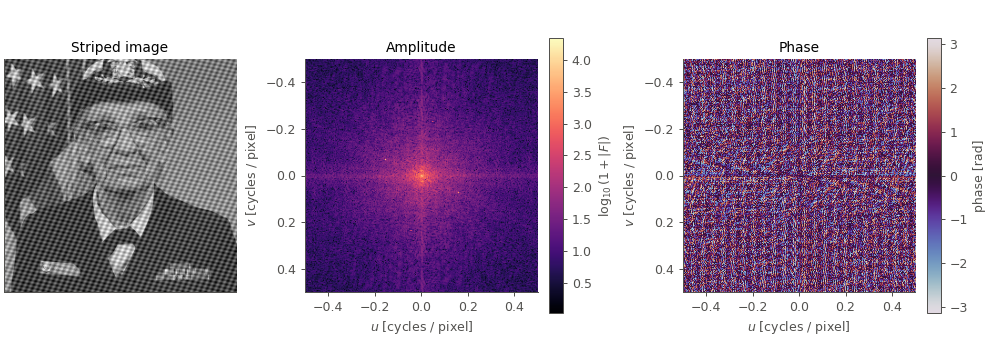

In [84]:
# Add two sets of interference stripes.
y, x = np.mgrid[:256, :256]
stripes = (0.25 * np.cos(2 * np.pi * (40 * x + 18 * y) / 256) +
           0.20 * np.cos(2 * np.pi * (-12 * x + 60 * y) / 256))
striped_hopper = hopper + stripes

ft_plot.show_spectrum(striped_hopper, 'Striped image')

In [85]:
##############################
# YOU NEED TO EDIT THIS CELL #
##############################

# Build a mask (same shape as the image, unshifted FFT order) that removes the stripes.
notch = None

# Display the result.
if notch is not None:
    cleaned = fourier_filter(striped_hopper, notch)
    ft_plot.show_images(
        [striped_hopper, cleaned, striped_hopper - cleaned],
        ['Striped', 'Cleaned', 'What was removed'],
    )

## Summary

* The FT measures how much of each sinusoid a signal contains by **projecting** onto it (the winding machine). **Amplitude** says how much; **phase** says where or when.
* The **continuous FT** is the mathematical ideal. The **DFT** maps $N$ samples to $N$ coefficients exactly, but sampling makes the spectrum periodic (**aliasing** above $f_s/2$) and a finite duration discretises frequency ($\Delta f = 1/T$, **leakage**).
* The **FFT** gives the identical result in $\mathcal{O}(N\log N)$ by recursively splitting into even and odd samples.
* Reading Fourier space: low frequencies (centre) are smooth, large-scale structure; high frequencies (edges) are fine detail and noise; narrow in one domain means wide in the other; shifts only change the phase; convolution becomes multiplication; orientation in 2D is preserved (and perpendicular to stripes and edges).
* Fourier space has **no localisation**: a coefficient describes the whole signal. Recovering *when* or *where* needs windowed transforms or wavelets.

## Further Resources

In [86]:
IFrame(src='https://www.youtube.com/embed/spUNpyF58BY', width=560, height=315)

* 3Blue1Brown, [*But what is a Fourier series?*](https://www.youtube.com/watch?v=r6sGWTCMz2k)
* S. W. Smith, [*The Scientist and Engineer's Guide to Digital Signal Processing*](https://www.dspguide.com/)
* R. Bracewell, *The Fourier Transform and Its Applications* (McGraw-Hill, 2000)
* J.-L. Starck, F. Murtagh and J. Fadili, [*Sparse Image and Signal Processing*](https://doi.org/10.1017/CBO9781316104514) (Cambridge, 2015)

---

## <font color='#fdbf00'>Hints</font>

**Exercise 1: Inverse DFT**

1. Winding forwards and backwards differ only by the sign of $i$: try a *conjugate* approach.
1. Don't forget the $1/N$.

<details><summary>Solution</summary>

```python
def idft(X):

    return dft_matrix(X.size).conj() @ X / X.size
```
</details>

**Exercise 2: Remove Periodic Noise**

1. Each set of stripes is a single plane wave, so look for isolated *bright spots* in the amplitude spectrum.
1. The stripe frequencies can be read straight off the code that made them: $(k_x, k_y) = (40, 18)$ and $(-12, 60)$.
1. A real image always has spikes in *pairs*, at $\pm(k_x, k_y)$.
1. The mask is in unshifted order: row index $k_y \bmod 256$, column index $k_x \bmod 256$.

<details><summary>Solution</summary>

```python
notch = np.ones(striped_hopper.shape)
for kx, ky in [(40, 18), (-12, 60)]:
    for sign in (1, -1):
        notch[(sign * ky) % 256, (sign * kx) % 256] = 0
```
</details>